In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import getpass
from pathlib import Path
from typing import Any, Optional, Tuple
import cv2 as cv

from sentinelhub import (
    SHConfig,
    DataCollection,
    SentinelHubCatalog,
    SentinelHubRequest,
    SentinelHubStatistical,
    BBox,
    bbox_to_dimensions,
    CRS,
    MimeType,
    Geometry,
)
config = SHConfig('Teledeteccion') 

In [8]:
aoi_coords_wgs84 = [-7.04641, 36.42570, -6.04641, 37.42570] # Coordenadas (latitud y longitud) de esquina 
                                                            # inferior izquierda y esquina superior derecha.
resolution = 100                                            # Resolución en metros
aoi_bbox = BBox(bbox=aoi_coords_wgs84, crs=CRS.WGS84)
aoi_size = bbox_to_dimensions(aoi_bbox, resolution=resolution)

print(f"Image shape at {resolution} m resolution: {aoi_size} pixels") # Para el ejemplo, de 1100x1100 px

Image shape at 100 m resolution: (862, 1133) pixels


Ejercicio 1

In [9]:
evalscript_true_color = """
    //VERSION=3

    function setup() {
        return {
            input: [{
                bands: ["B02", "B03", "B04"]
            }],
            output: {
                bands: 3,
            }
        };
    }

    function evaluatePixel(sample) {
        return [sample.B04, sample.B03, sample.B02];
    }
"""

evalscript_false_color = """
//VERSION=3

function setup() {
    return {
        input: [{
            bands: ["B08", "B04", "B03"],
            units: "REFLECTANCE"
        }],
        output: {
            bands: 3
        }
    };
}

function evaluatePixel(s) {
    return [s.B08, s.B04, s.B03];
}
"""



request_true = SentinelHubRequest(
    evalscript=evalscript_true_color,
    input_data=[
        SentinelHubRequest.input_data(
            data_collection=DataCollection.SENTINEL2_L2A.define_from(
                name="s2l2a", service_url="https://sh.dataspace.copernicus.eu"
            ),
            time_interval=("2025-10-20", "2025-11-20"),
            other_args={"dataFilter": {"mosaickingOrder": "leastCC"}},
        )
    ],
    responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
    bbox=aoi_bbox,
    size=aoi_size,
    config=config,
)

request_false = SentinelHubRequest(
    evalscript=evalscript_false_color,
    input_data=[
        SentinelHubRequest.input_data(
            data_collection=DataCollection.SENTINEL2_L2A.define_from(
                name="s2l2a", service_url="https://sh.dataspace.copernicus.eu"
            ),
            time_interval=("2025-10-20", "2025-11-20"),
            other_args={"dataFilter": {"mosaickingOrder": "leastCC"}},
        )
    ],
    responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
    bbox=aoi_bbox,
    size=aoi_size,
    config=config,
)

In [11]:
truecolor = request_true.get_data()[0]
falsecolor = request_false.get_data()[0]

def Histograma(img):
    pix, frec = np.unique(img, return_counts=True)
    return pix, frec

def expan(img, cmin, cmax):
    res = img.astype(np.float64).copy()
    for i in range(res.shape[0]):
        for j in range(res.shape[1]):
            px = res[i, j]
            if px <= cmin:
                res[i, j] = 0
            elif px >= cmax:
                res[i, j] = 255
            else:
                res[i, j] = (px - cmin) * (255.0 / (cmax - cmin))
    return res.astype(np.uint8)

def corte(img, porc):
    pixel, frec = Histograma(img)

    total = sum(frec)
    desc = total * porc

    # corte inferior
    acum = 0
    for p, f in zip(pixel, frec):
        acum += f
        if acum >= desc:
            cmin = p
            break

    # corte superior
    acum = 0
    for p, f in zip(reversed(pixel), reversed(frec)):
        acum += f
        if acum >= desc:
            cmax = p
            break

    return expan(img, cmin, cmax)

def aplicarCorte(img, porc=0.01):
    r, g, b = cv.split(img)

    r2 = corte(r, porc)
    g2 = corte(g, porc)
    b2 = corte(b, porc)

    return cv.merge([r2, g2, b2])

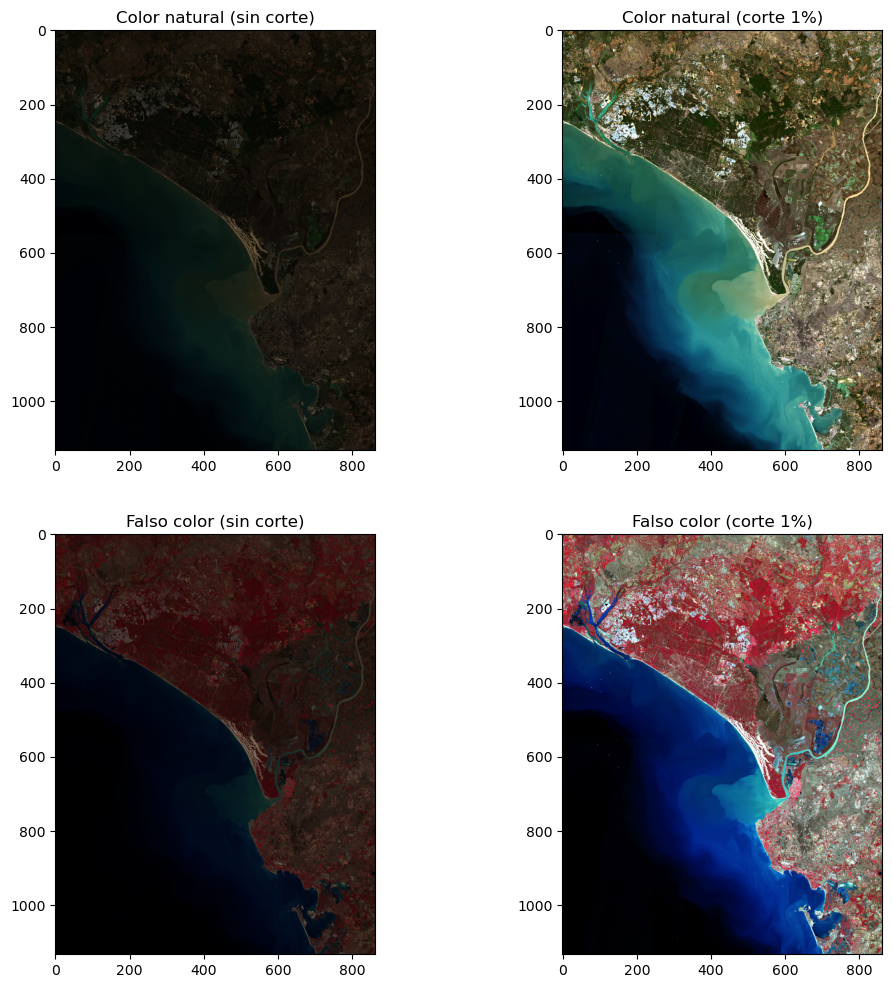

In [12]:
tccorte = aplicarCorte(truecolor)
fccorte = aplicarCorte(falsecolor)

fig, axs = plt.subplots(2, 2, figsize=(12, 12))

axs[0, 0].imshow(truecolor)
axs[0, 0].set_title("Color natural (sin corte)")

axs[0, 1].imshow(tccorte)
axs[0, 1].set_title("Color natural (corte 1%)")

axs[1, 0].imshow(falsecolor)
axs[1, 0].set_title("Falso color (sin corte)")

axs[1, 1].imshow(fccorte)
axs[1, 1].set_title("Falso color (corte 1%)")

plt.show()

Ejercicio 2: HSV

Text(0.5, 1.0, 'False color (RGB corte)')

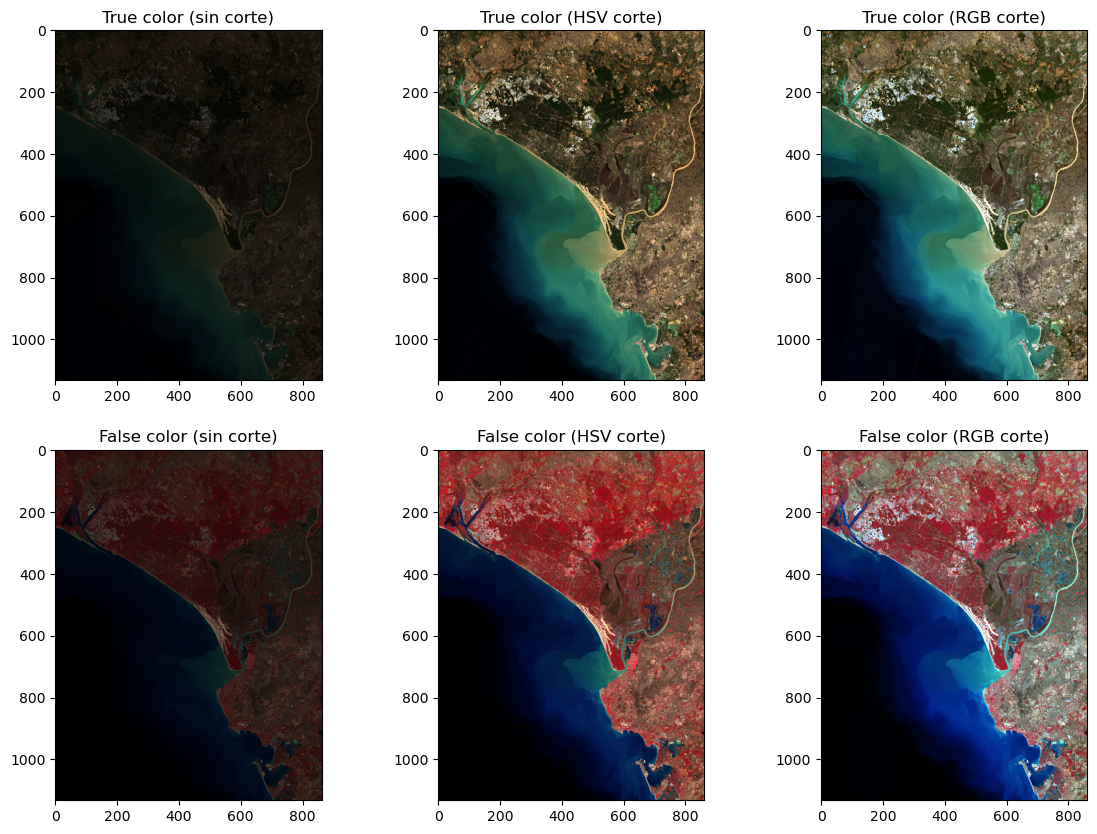

In [18]:
def cortehsv(img, por=0.01):

    # Convertimos a HSV
    hsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)
    h, s, v = cv.split(hsv)

    v2 = corte(v, por)  

    hsv_mod = cv.merge([h, s, v2])

    # Volvemos a RGB
    rgb_mod = cv.cvtColor(hsv_mod, cv.COLOR_HSV2RGB)
    return rgb_mod


fig, axs = plt.subplots(2, 3, figsize=(14, 10))

axs[0, 0].imshow(truecolor)
axs[0, 0].set_title("True color (sin corte)")

axs[0, 1].imshow(tccortehsv)
axs[0, 1].set_title("True color (HSV corte)")

axs[0, 2].imshow(tccorte)
axs[0, 2].set_title("True color (RGB corte)")

axs[1, 0].imshow(falsecolor)
axs[1, 0].set_title("False color (sin corte)")

axs[1, 1].imshow(fccortehsv)
axs[1, 1].set_title("False color (HSV corte)")

axs[1, 2].imshow(fccorte)
axs[1, 2].set_title("False color (RGB corte)")


Ejercicio 3: NDVI

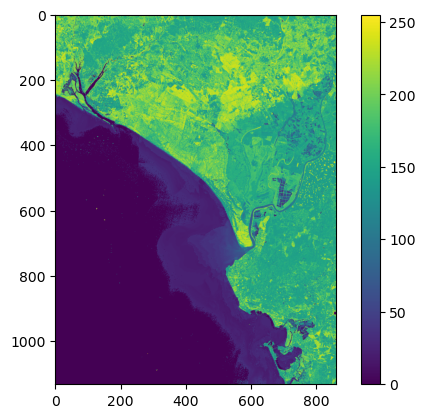

In [21]:
def ndvi_calc(rgb_img, faux_img):
    # Extraemos bandas
    canal_R, canal_G, canal_B = cv.split(rgb_img)
    banda_NIR, banda_R2, banda_G2 = cv.split(faux_img)

    # Convertimos a float para evitar problemas en divisiones
    N = banda_NIR.astype(np.float64)
    R = canal_R.astype(np.float64)

    filas, cols = N.shape
    resultado = np.zeros((filas, cols), dtype=np.float64)

    # Cálculo píxel a píxel del NDVI
    for f in range(filas):
        for c in range(cols):
            valN = N[f, c]
            valR = R[f, c]
            suma = valN + valR

            if suma != 0:
                nd = (valN - valR) / suma
                resultado[f, c] = (nd + 1) * 127.5   # Escalamos a [0,255]

    return resultado.astype(np.uint8)

ndvi = ndvi_calc(truecolor, falsecolor)

im=plt.imshow(ndvi)
plt.colorbar(im)
plt.show()

Ejercicio 4: DS

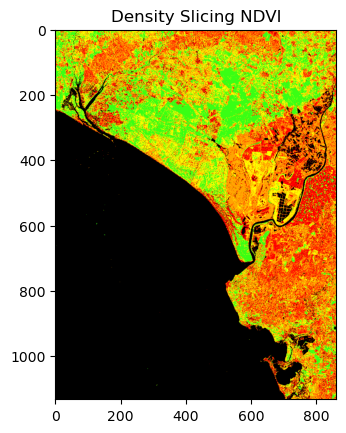

In [28]:
def densi(nd_img):
    # Imagen RGB de salida
    salida = np.zeros((nd_img.shape[0], nd_img.shape[1], 3), dtype=np.uint8)

    # Rangos NDVI (0–255)
    t1, t2, t3, t4 = 128, 150, 175, 200

    # Colores asociados
    c_negro        = [0, 0, 0]
    c_rojo         = [255, 0, 0]
    c_naranja      = [255, 165, 0]
    c_amarillo     = [255, 255, 0]
    c_verde_fos    = [57, 255, 20]

    # Asignación de clases (density slicing)
    salida[(nd_img >=   0) & (nd_img <  t1)] = c_negro
    salida[(nd_img >=  t1) & (nd_img <  t2)] = c_rojo
    salida[(nd_img >=  t2) & (nd_img <  t3)] = c_naranja
    salida[(nd_img >=  t3) & (nd_img <  t4)] = c_amarillo
    salida[(nd_img >=  t4)]                  = c_verde_fos

    return salida

ds = densi(ndvi)

plt.imshow(ds)
plt.title("Density Slicing NDVI")
plt.show()


Ejercicio 5: Clasificación

Number of elements assigned to each cluster: [528511 448135]


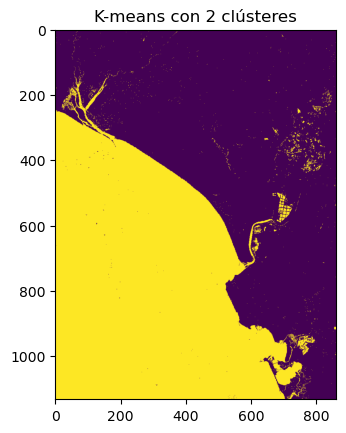

In [30]:
from sklearn.cluster import KMeans

flat = ndvi.reshape(-1, 1)

kmeans = KMeans(
    n_clusters=2,   # 2 clústeres, como pide el ejercicio
    max_iter=100,
    n_init=1,
    random_state=1
).fit(flat)

cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")

plt.imshow(kmeans.labels_.reshape(1133, 862))
plt.title("K-means con 2 clústeres")
plt.show()
